# Week (2) Module B: Statistical Inference, Confidence Intervals & Hypothesis Testing
**Course:** Statistics and Machine Learning

---

### Module Contributor(s)
| Full Name | Role |
|---|---|
| `_______________` | `_______________` |
| `_______________` | `_______________` |

---

### About this Module
This module covers **Tasks 4, 5, and 6** of the Week (2) practical.
Your outputs will be merged with **Modules A, C, and D into the group's final notebook**.

**Dataset:** Pima Indians Diabetes → DOI: https://www.openml.org/d/37

| Feature | Description |
|---|---|
| `Pregnancies` | Number of pregnancies |
| `Glucose` | Plasma glucose concentration |
| `BloodPressure` | Diastolic blood pressure (mm Hg) |
| `SkinThickness` | Triceps skin fold thickness (mm) |
| `Insulin` | 2-hour serum insulin (mu U/ml) |
| `BMI` | Body mass index |
| `DiabetesPedigreeFunction` | Genetic risk score |
| `Age` | Age in years |
| `Outcome` | 0 = Non-diabetic, 1 = Diabetic |

---

**Background: Day 3 (Week 1) lecture recap:**

Module A showed that samples vary. Module B uses that variation to make principled, quantified decisions about the population.

> - **Statistical inference:** using sample data to estimate population values and test whether observed differences are likely to be real or due to random chance.
> - **Confidence intervals (CI):** instead of a single point estimate, a CI gives a *range* of plausible values for the population parameter. A 95% CI does not mean a 95% probability. However, it means that 95% of such intervals, constructed from repeated samples, would contain the true parameter.
> - **Hypothesis testing:** we set up H₀ (no effect) and H₁ (effect exists), then compute a p-value. A small p-value (< 0.05) is evidence against H₀. This does NOT prove H₁, and it does NOT measure the size or importance of an effect.
> - **Correlation:** Pearson r measures the strength and direction of a *linear* relationship between two continuous variables (range −1 to +1). Correlation does not imply causation.

---
> Cells marked `# TODO` require code. Cells marked `✍️` require a written response.

---
# Task 4: Confidence Intervals (Estimate + Uncertainty)
A point estimate (e.g. sample mean = 121) gives one number. A confidence interval says: 'the true mean is plausibly between 117 and 125.' The interval makes our uncertainty explicit.

> **Goal:** Construct 95% confidence intervals for mean Glucose and mean BMI, verify coverage empirically, and visualise the result.

In [27]:
# ── Task 4 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats   # stats.t.interval: computes exact t-based confidence intervals

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Replace impossible zeros in clinical measurements with NaN.
# A Glucose or BMI of 0 is physically impossible: these are missing values disguised as zeros.
# We must remove them BEFORE computing any CIs or tests, or the results will be distorted.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

np.random.seed(42)  # RANDOM_STATE=42 used across all modules for consistency
print('Ready')

Ready


In [28]:
# Provided: construct a 95% CI for mean Glucose from a single sample of n=60

# Step 1: Draw a random sample of non-missing Glucose values.
glucose_clean = df['Glucose'].dropna()            # remove NaN rows before sampling
sample_glucose = glucose_clean.sample(n=60, random_state=42)

# Step 2: Compute the sample mean and standard error.
#   x_bar: our best single estimate of the population mean
#   se   : how much the sample mean would vary across repeated samples
#          SE = s / sqrt(n)  where s is the sample standard deviation (ddof=1)
x_bar = sample_glucose.mean()
se    = sample_glucose.std(ddof=1) / np.sqrt(len(sample_glucose))

# Step 3: Use the t-distribution (not Normal) to compute the CI.
#   Why t? Because we are estimating the population std from the sample.
#   For large n (>100) t ≈ z, but t is always the safer choice.
#   df = n - 1: degrees of freedom (one is 'used up' estimating the mean)
#   loc = x_bar: centre of the distribution
#   scale = se : standard deviation of the sampling distribution
ci_low, ci_high = stats.t.interval(
    confidence=0.95,
    df=len(sample_glucose) - 1,
    loc=x_bar,
    scale=se
)

true_mean_glucose = glucose_clean.mean()   # benchmark: the 'true' population mean

print('--- 95% Confidence Interval for Mean Glucose (sample n=60) ---')
print(f'Sample mean        : {x_bar:.2f} mg/dL')
print(f'95% CI             : [{ci_low:.2f}, {ci_high:.2f}] mg/dL')
print(f'CI width           : {ci_high - ci_low:.2f} mg/dL')
print(f'True population mean: {true_mean_glucose:.2f} mg/dL')
print(f'Does the CI contain the true mean? {ci_low <= true_mean_glucose <= ci_high}')


--- 95% Confidence Interval for Mean Glucose (sample n=60) ---
Sample mean        : 127.55 mg/dL
95% CI             : [119.10, 136.00] mg/dL
CI width           : 16.91 mg/dL
True population mean: 121.69 mg/dL
Does the CI contain the true mean? True


In [29]:
# TODO: Construct a 95% CI for mean BMI for Diabetic patients only.
#
# This is a common clinical question: 'What is the average BMI of diabetic patients?'
# Using all patients would mix two populations: diabetic and non-diabetic.
#
# Steps:
#   1. Filter to rows where Outcome==1 AND BMI is not NaN.
#      Use: df[(df['Outcome'] == 1) & (df['BMI'].notna())]['BMI']
#   2. Draw a random sample of n=50 from the filtered data (random_state=42).
#   3. Compute x_bar and se exactly as shown in the provided cell.
#   4. Call stats.t.interval(confidence=0.95, ...) to get ci_low and ci_high.
#   5. Compute true_mean_bmi_diabetic = mean of ALL non-NaN BMI values for Diabetics.
#   6. Print: sample mean, CI bounds, CI width, true mean, and whether the CI contains it.

# YOUR CODE HERE


In [30]:
# TODO: Simulate CI coverage: show that 95% CIs capture the true mean ~95% of the time.
#
# This demonstrates the CORRECT interpretation of a confidence interval:
# 'If we repeated this study 100 times, about 95 of the intervals would contain the true mean.'
#
# Steps:
#   1. Set true_mean = glucose_clean.mean() (the 'population' mean).
#   2. Repeat 200 times:
#        a. Draw a random sample of n=40 from glucose_clean.
#        b. Compute the 95% CI using stats.t.interval().
#        c. Record (ci_low, ci_high, ci_low <= true_mean <= ci_high) in a list called results.
#   3. Plot all 200 CIs as horizontal line segments using plt.hlines():
#        - Colour each line green if it contains true_mean, red if it does not.
#   4. Draw a vertical blue dashed line at true_mean.
#   5. Print the empirical coverage: what % of the 200 CIs contained the true mean.
#
# Hint for plt.hlines:
#   plt.hlines(y=i, xmin=lo, xmax=hi, colors=colour, linewidth=1)

# YOUR CODE HERE


### ✍️ Interpretation: Task 4

1. A student writes: *'There is a 95% probability that the true mean Glucose lies inside my confidence interval.'* Explain precisely why this statement is incorrect and provide the correct interpretation.
2. You computed CIs for Glucose (all patients) and BMI (Diabetic patients only). Which CI was wider and why? (Think about sample size and variability.)
3. In the coverage simulation, did exactly 95 out of 200 CIs contain the true mean? What does it mean if the empirical coverage is 93% or 97%?

> *Your answer here:*

---
# Task 5: Hypothesis Testing (t-test & ANOVA)
Confidence intervals estimate *where* a parameter lies. Hypothesis tests decide whether an observed difference is *statistically distinguishable from zero*.

> **Goal:** Test whether Glucose and BMI differ significantly between Diabetic and Non-Diabetic patients (t-test), and whether Glucose differs across three age groups (ANOVA).

In [31]:
# ── Task 5 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Clean impossible zeros before any inferential test.
# Zeros in these columns are missing values that would corrupt the test statistics.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

# Create three age groups for the ANOVA in this task.
# pd.cut() divides a continuous variable into labelled intervals.
# right=True means the interval is (lower, upper]: the upper bound is included.
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[20, 35, 50, 82],
    labels=['Young (21-35)', 'Middle (36-50)', 'Senior (51+)'],
    right=True
)

print('Age group distribution:')
print(df['AgeGroup'].value_counts().sort_index())
print('Ready')


Age group distribution:
AgeGroup
Young (21-35)     498
Middle (36-50)    189
Senior (51+)       81
Name: count, dtype: int64
Ready


--- Group descriptives ---
Diabetic        n=266  mean=142.32  std=29.60
Non-Diabetic    n=497  mean=110.64  std=24.78

--- Welch t-test: Glucose ---
t-statistic : 14.8844
p-value     : 2.84e-41

Conclusion: p=2.84e-41 < α=0.05 → Reject H₀.
The data provide strong evidence that mean Glucose differs between groups.
(Note: this does NOT prove that high Glucose CAUSES diabetes.)


C:\Users\kofia\AppData\Local\Temp\ipykernel_58044\2867950635.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=['Glucose']), x='DiabetesStatus', y='Glucose',


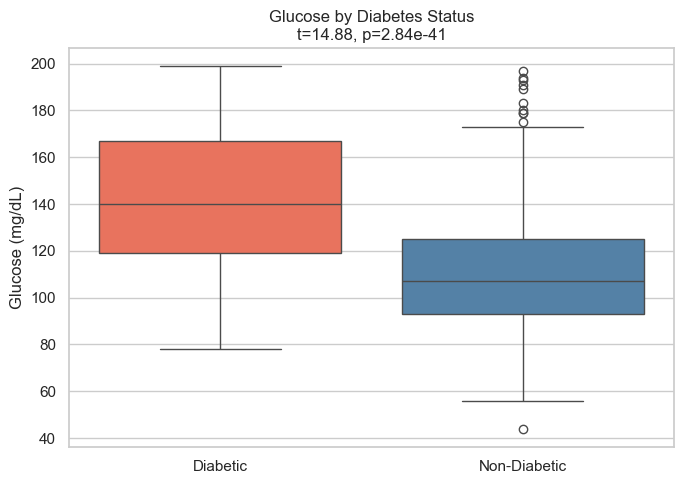

In [32]:
# Provided: independent t-test Glucose: Diabetic vs Non-Diabetic

# --- Hypotheses ---
# H₀: Mean Glucose is the same in Diabetic and Non-Diabetic patients.
# H₁: Mean Glucose differs between the two groups.

# Separate the two groups and drop NaN values.
# dropna() is essential: stats.ttest_ind cannot handle NaN and will return NaN results.
group_diab     = df.loc[df['Outcome'] == 1, 'Glucose'].dropna()
group_nondiab  = df.loc[df['Outcome'] == 0, 'Glucose'].dropna()

print('--- Group descriptives ---')
for name, grp in [('Diabetic', group_diab), ('Non-Diabetic', group_nondiab)]:
    print(f'{name:<14}  n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run Welch's t-test (equal_var=False).
# Welch's version does NOT assume equal variances in both groups.
t_stat, p_value = stats.ttest_ind(group_diab, group_nondiab, equal_var=False)

print('\n--- Welch t-test: Glucose ---')
print(f't-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05
if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('The data provide strong evidence that mean Glucose differs between groups.')
    print('(Note: this does NOT prove that high Glucose CAUSES diabetes.)')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')

# Visualise with a boxplot: shows median, spread, and outliers at a glance.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df.dropna(subset=['Glucose']), x='DiabetesStatus', y='Glucose',
            palette={'Non-Diabetic': 'steelblue', 'Diabetic': 'tomato'}, ax=ax)
ax.set_title(f'Glucose by Diabetes Status\nt={t_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('')
ax.set_ylabel('Glucose (mg/dL)')
plt.tight_layout()
plt.show()


--- Group descriptives ---
Diabetic        n=266  mean=35.41  std=6.61
Non-Diabetic    n=491  mean=30.86  std=6.56

--- Welch t-test: BMI ---
t-statistic : 9.0550
p-value     : 2.48e-18

Conclusion: p=2.48e-18 < α=0.05 → Reject H₀.
The data provide strong evidence that mean BMI differs between groups.
(Note: this does NOT prove that high BMI CAUSES diabetes.)


C:\Users\kofia\AppData\Local\Temp\ipykernel_58044\729358072.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=['BMI']), x='DiabetesStatus', y='BMI',


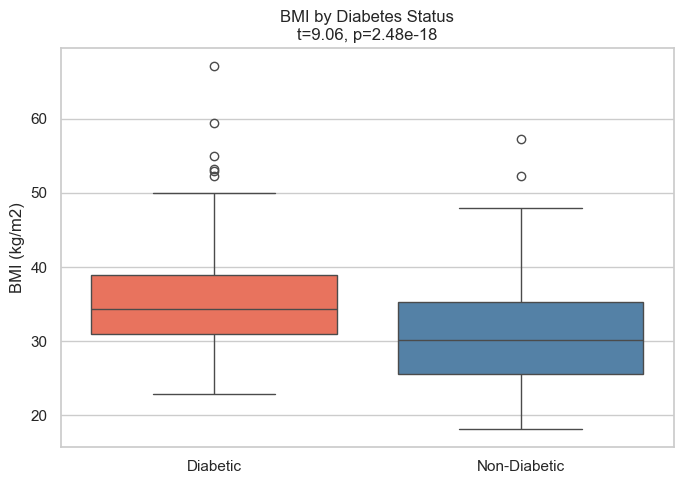

In [33]:
# TODO: Run the same t-test comparing BMI between Diabetic and Non-Diabetic patients.
#
# Steps (mirror the Glucose t-test above exactly):
#   1. Extract group_diab_bmi and group_nondiab_bmi from the BMI column, dropping NaN.
#   2. Print group descriptives (n, mean, std) for both groups.
#   3. State H₀ and H₁ as print statements.
#   4. Run stats.ttest_ind(..., equal_var=False).
#   5. Print t-statistic, p-value, and a conclusion sentence.
#   6. Plot a side-by-side boxplot of BMI by DiabetesStatus.

# YOUR CODE HERE

# Provided: independent t-test Glucose: Diabetic vs Non-Diabetic

# --- Hypotheses ---
# H₀: Mean Glucose is the same in Diabetic and Non-Diabetic patients.
# H₁: Mean Glucose differs between the two groups.

# Separate the two groups and drop NaN values.
# dropna() is essential: stats.ttest_ind cannot handle NaN and will return NaN results.
group_diab_bmi     = df.loc[df['Outcome'] == 1, 'BMI'].dropna()
group_nondiab_bmi  = df.loc[df['Outcome'] == 0, 'BMI'].dropna()

print('--- Group descriptives ---')
for name, grp in [('Diabetic', group_diab_bmi), ('Non-Diabetic', group_nondiab_bmi)]:
    print(f'{name:<14}  n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run Welch's t-test (equal_var=False).
# Welch's version does NOT assume equal variances in both groups.
t_stat, p_value = stats.ttest_ind(group_diab_bmi, group_nondiab_bmi, equal_var=False)

print('\n--- Welch t-test: BMI ---')
print(f't-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05
if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('The data provide strong evidence that mean BMI differs between groups.')
    print('(Note: this does NOT prove that high BMI CAUSES diabetes.)')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')

# Visualise with a boxplot: shows median, spread, and outliers at a glance.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df.dropna(subset=['BMI']), x='DiabetesStatus', y='BMI',
            palette={'Non-Diabetic': 'steelblue', 'Diabetic': 'tomato'}, ax=ax)
ax.set_title(f'BMI by Diabetes Status\nt={t_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('')
ax.set_ylabel('BMI (kg/m2)')
plt.tight_layout()
plt.show()



--- Hypotheses ---
H₀: Mean Glucose is the same across all age groups.
H₁: At least one age group has a different mean Glucose.

--- Group descriptives ---
Young    n=495  mean=116.50  std=28.02
Middle   n=187  mean=127.62  std=32.67
Senior   n=81  mean=139.68  std=31.26

--- One-Way ANOVA: Glucose by Age Group ---
F-statistic : 26.3765
p-value     : 8.41e-12

Conclusion: p=8.41e-12 < α=0.05 → Reject H₀.
There is strong evidence that mean Glucose differs among the age groups.


C:\Users\kofia\AppData\Local\Temp\ipykernel_58044\1626056173.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


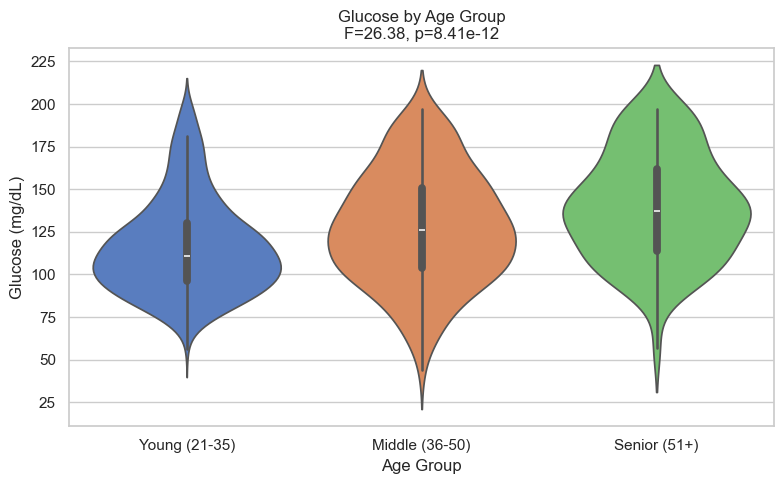

In [34]:
# TODO: One-way ANOVA: test whether mean Glucose differs across the three age groups.
#
# Why ANOVA instead of multiple t-tests?
# Running three separate t-tests (Young vs Middle, Young vs Senior, Middle vs Senior)
# inflates the false-positive rate. With α=0.05, three tests give a ~14% chance of at
# least one false positive. ANOVA controls this by testing all groups simultaneously.
#
# Steps:
#   1. Create three arrays: glucose for Young, Middle, Senior: each with NaN dropped.
#      Use df.loc[df['AgeGroup'] == 'Young (21-35)', 'Glucose'].dropna()
#   2. Print group descriptives (n, mean, std) for all three groups.
#   3. State H₀ and H₁ as print statements.
#   4. Run stats.f_oneway(young_glucose, middle_glucose, senior_glucose).
#      This returns (F_statistic, p_value).
#   5. Print F-statistic, p-value, and a one-sentence conclusion.
#   6. Plot a violin plot (sns.violinplot) of Glucose by AgeGroup.
#      A violin plot shows both the distribution shape and the median, making it
#      more informative than a boxplot for ANOVA visualisation.

# YOUR CODE HERE
# --- Hypotheses ---
print('--- Hypotheses ---')
print('H₀: Mean Glucose is the same across all age groups.')
print('H₁: At least one age group has a different mean Glucose.\n')

# Separate glucose values for each age group and drop missing values
young_glucose = df.loc[df['AgeGroup'] == 'Young (21-35)', 'Glucose'].dropna()
middle_glucose = df.loc[df['AgeGroup'] == 'Middle (36-50)', 'Glucose'].dropna()
senior_glucose = df.loc[df['AgeGroup'] == 'Senior (51+)', 'Glucose'].dropna()

# Print descriptive statistics
print('--- Group descriptives ---')
for name, grp in [('Young', young_glucose),
                  ('Middle', middle_glucose),
                  ('Senior', senior_glucose)]:
    print(f'{name:<8} n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run One-Way ANOVA
F_stat, p_value = stats.f_oneway(
    young_glucose,
    middle_glucose,
    senior_glucose
)

print('\n--- One-Way ANOVA: Glucose by Age Group ---')
print(f'F-statistic : {F_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05

if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('There is strong evidence that mean Glucose differs among the age groups.')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')
    print('There is insufficient evidence that mean Glucose differs among the age groups.')

# Violin plot
fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=df.dropna(subset=['Glucose']),
    x='AgeGroup',
    y='Glucose',
    palette='muted',
    ax=ax
)

ax.set_title(f'Glucose by Age Group\nF={F_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('Age Group')
ax.set_ylabel('Glucose (mg/dL)')

plt.tight_layout()
plt.show()

### ✍️ Interpretation: Task 5

1. The Glucose t-test produced an extremely small p-value (e.g. 1e-22). Does this mean the difference is clinically *important*? What additional measure would you report to assess practical significance?
2. For the BMI t-test: state the result in one non-technical sentence that a doctor could understand (avoid the word 'p-value').
3. The ANOVA tells you *that* at least one age group differs in mean Glucose, but not *which* groups. What is the name of the follow-up procedure used to identify which specific pairs differ?

> *Your answer here:*
1. A very small p-value does not necessarily mean the difference is clinically important. It only indicates that the observed difference is unlikely to be due to chance. To assess practical or clinical significance, I would report a 95% confidence interval for the difference in mean glucose levels.
2. Patients with diabetes had a higher average BMI than patients without diabetes, suggesting that higher body weight is associated with diabetes in this dataset.
3. The follow-up procedure is called a post hoc test, which essentially compares age groups with a significant difference

---
# Task 6: Correlation Analysis (Pearson's r)
Correlation measures the *strength and direction* of a linear relationship between two continuous variables. It is the first step before building any regression model.

> **Goal:** Compute the full Pearson correlation matrix for the Diabetes features, perform a formal correlation test between key variables, and visualise the results.

In [35]:
# ── Task 6 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

# Numeric columns for the correlation matrix (exclude the string 'DiabetesStatus' column).
NUMERIC_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
                'Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']

print('Ready')


Ready


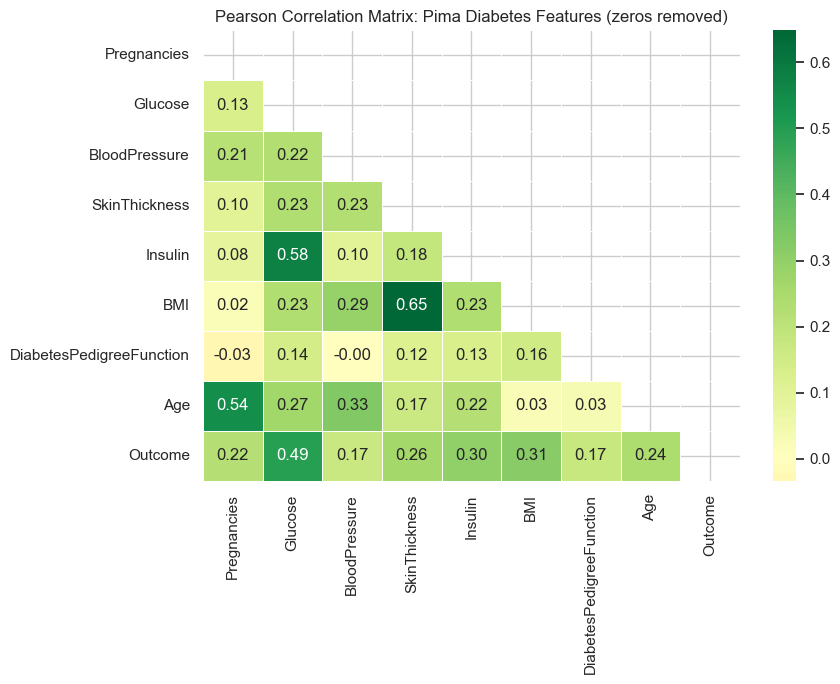


Features ranked by |r| with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


In [36]:
# Provided: Pearson correlation matrix heatmap

# df.corr() computes Pearson r for every pair of numeric columns.
# NaN values are dropped pairwise, each pair uses all rows where both values are present.
corr_matrix = df[NUMERIC_COLS].corr()

# Create an upper-triangle mask so we only display the lower half of the matrix.
# The matrix is symmetric (r(X,Y) = r(Y,X)), so the upper half is redundant.
upper_tri = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    mask=upper_tri,    # hide the upper triangle
    annot=True,        # print r values inside each cell
    fmt='.2f',         # format to 2 decimal places
    cmap='RdYlGn',     # red = negative, yellow = near zero, green = positive
    center=0,          # white at r=0 for easy visual interpretation
    linewidths=0.5,    # thin lines between cells
    ax=ax
)
ax.set_title('Pearson Correlation Matrix: Pima Diabetes Features (zeros removed)')
plt.tight_layout()
plt.show()

# Rank all features by their absolute correlation with the target (Outcome).
outcome_corr = corr_matrix['Outcome'].drop('Outcome').abs().sort_values(ascending=False)
print('\nFeatures ranked by |r| with Outcome:')
print(outcome_corr.round(3).to_string())


In [37]:
# TODO: Formal Pearson correlation test between Glucose and BMI.
#
# Unlike df.corr() (which only gives r), stats.pearsonr() also gives the p-value,
# which tells us whether the correlation is statistically distinguishable from zero.
#
# Steps:
#   1. Drop rows where EITHER Glucose OR BMI is NaN.
#      Use df.dropna(subset=['Glucose', 'BMI']).
#   2. Run stats.pearsonr(x, y), it returns (r, p_value).
#   3. Print: r rounded to 4 decimal places, p-value, and a plain-English conclusion.
#      Include: is |r| small (< 0.1), moderate (0.1–0.3), or strong (> 0.3)?
#   4. Create a scatter plot (Glucose on x-axis, BMI on y-axis):
#        - Colour points by DiabetesStatus (use hue= in sns.scatterplot).
#        - Overlay a linear trend line using sns.regplot() with scatter=False.
#        - Add r and p-value to the title.

# YOUR CODE HERE


In [38]:
# TODO: Build a ranked correlation table, all features vs Outcome.
#
# For each feature in NUMERIC_COLS (excluding 'Outcome'), compute:
#   - Pearson r vs Outcome using stats.pearsonr()
#   - the corresponding p-value
#   - a boolean: is p < 0.05?
#
# Steps:
#   1. Start with an empty list called records.
#   2. Loop over each feature in NUMERIC_COLS (skip 'Outcome'):
#        a. Drop NaN in both the feature and 'Outcome' column simultaneously.
#        b. Run stats.pearsonr().
#        c. Append a dict {'Feature': ..., 'r': ..., 'p-value': ...,
#                          'Significant (α=0.05)': ...} to records.
#   3. Create a DataFrame from records.
#   4. Sort by absolute r value (descending).
#   5. Round r to 4 dp and p-value to 6 dp.
#   6. Print the full table.

# YOUR CODE HERE

# Build a ranked correlation table: all features vs Outcome

# Step 1: Create an empty list
records = []

# Step 2: Loop through each feature (excluding Outcome)
for feature in NUMERIC_COLS:
    if feature == 'Outcome':
        continue

    # Drop rows with missing values in either column
    temp = df[[feature, 'Outcome']].dropna()

    # Compute Pearson correlation and p-value
    r, p = stats.pearsonr(temp[feature], temp['Outcome'])

    # Store the results
    records.append({
        'Feature': feature,
        'r': r,
        'p-value': p,
        'Significant (α=0.05)': p < 0.05
    })

# Step 3: Convert to DataFrame
corr_table = pd.DataFrame(records)

# Step 4: Sort by absolute correlation (largest first)
corr_table = corr_table.reindex(
    corr_table['r'].abs().sort_values(ascending=False).index
)

# Step 5: Round values
corr_table['r'] = corr_table['r'].round(4)
corr_table['p-value'] = corr_table['p-value'].round(6)

# Step 6: Print the full table
print("\nRanked Pearson Correlation with Outcome")
print(corr_table.to_string(index=False))



Ranked Pearson Correlation with Outcome
                 Feature      r  p-value  Significant (α=0.05)
                 Glucose 0.4947 0.000000                  True
                     BMI 0.3137 0.000000                  True
                 Insulin 0.3035 0.000000                  True
           SkinThickness 0.2595 0.000000                  True
                     Age 0.2384 0.000000                  True
             Pregnancies 0.2219 0.000000                  True
DiabetesPedigreeFunction 0.1738 0.000001                  True
           BloodPressure 0.1706 0.000003                  True


### ✍️ Interpretation: Task 6

1. Which feature has the strongest linear correlation with Outcome (diabetes)? Does this match what you would expect clinically? Does a strong correlation mean this feature *causes* diabetes?
2. Glucose and BMI are statistically significantly correlated (p < 0.05). Looking at the scatter plot, does the relationship look strongly linear, or are there patterns a straight line would miss?
3. Two features might both correlate with Outcome but also correlate with *each other*, this is called *multicollinearity*. From the heatmap, identify one pair of features that are highly correlated with each other. What problem does this cause when building a predictive model?

> *Your answer here:*

---
## 📋 Module B: Handoff Summary

Complete this table before merging with your group.

| Item | Your finding |
|---|---|
| 95% CI for mean Glucose (sample n=60) | [???, ???] mg/dL |
| 95% CI for mean BMI (Diabetic only) | [???, ???] |
| Empirical CI coverage (200 simulations) | ???% |
| t-test Glucose: t-statistic, p-value | t=???, p=??? |
| t-test BMI: t-statistic, p-value | t=???, p=??? |
| ANOVA Glucose across age groups: F, p | F=???, p=??? |
| Strongest predictor of Outcome (|r|) | ??? (r=???) |
| Pearson r: Glucose vs BMI | r=???, p=??? |

> Fill in the table above before handing off to the group.